# 1. Preprocesamiento y Análisis Exploratorio de Datos (EDA)

**Materia:** Aprendizaje Automático (Machine Learning)  
**Trabajo Práctico 2:** Clasificación Supervisada  
**Dataset:** Bank Marketing (UCI / Kaggle)  
**Objetivo de este cuaderno:** Unificar de forma rigurosa, modular y estructurada las etapas de ingesta, auditoría de calidad de datos, limpieza, partición preventiva contra *data leakage*, exploración estadística visual, ingeniería de características (pipeline de codificación sin escalado prematuro) y selección dimensional de variables orientada a los modelos supervisados del proyecto (Random Forest, SVM, Naive Bayes y KNN).

---

### Estructura del Cuaderno:
1. **Configuración del Entorno e Importación de Librerías:** Centralización de dependencias, configuración gráfica y rutas del proyecto (`data/` y `figures/`).
2. **Ingesta de Datos e Inspección Inicial:** Carga robusta del dataset delimitado por punto y coma (`;`).
3. **Auditoría de Calidad, Detección de Inconsistencias y Limpieza:** Detección de valores nulos, eliminación de registros duplicados y validación de reglas de dominio.
4. **Partición de Datos (Train / Test Split - 80/20 estratificado):** División temprana para evitar fuga de información (*data leakage*).
5. **Análisis Crítico de Fuga de Información (*Data Leakage*): Exclusión de `duration`:** Justificación operativa y eliminación de la variable de duración telefónica.
6. **Análisis Exploratorio de Datos (EDA) sobre el Conjunto de Entrenamiento:**
   - **6.1 Balance de la Variable Objetivo (`y`):** Análisis independiente del desbalance de clases y sus implicaciones para la evaluación.
   - **6.2 Auditoría de Crédito en Mora (`default`):** Análisis independiente de la cuasi-constancia y distribución de la variable de solvencia crediticia.
   - **6.3 Distribuciones Univariadas Completas:** Histogramas continuos, PMF de aguja para variables discretas/macro y PMF de barras para categóricas.
   - **6.4 Diagnóstico de Valores Atípicos (*Outliers*).**
7. **Pipeline de Preprocesamiento y Transformación de Características:**
   - Codificación ordinal, ternaria escalada, binaria y *One-Hot Encoding*.
   - **Conservación de escalas originales en variables continuas (sin estandarizar)** para prevenir *data leakage* en etapas posteriores de validación cruzada ($k$-fold CV).
   - Ajuste estricto sobre `X_train` y aplicación a `X_train` y `X_test`.
8. **Análisis de Dimensionalidad y Diagnóstico de Multicolinealidad:**
   - Filtrado de varianza cuasi-cero (*Near-Zero Variance*).
   - Relevancia no lineal mediante Información Mutua ($I(X; Y)$).
   - Matriz de dependencia inter-características (*Normalized Mutual Information*).
   - Diagnóstico de colinealidad con el Factor de Inflación de la Varianza (*VIF*) con término constante.
9. **Construcción y Exportación de Subconjuntos Curados en la Carpeta `data/`:**
   - *Set 1 (High-Capacity)*: Optimizado para *Random Forest*.
   - *Set 2 (Collinearity-Resolved Core)*: Optimizado para *SVM* y *Gaussian Naive Bayes*.
   - *Set 3 (Minimalist Orthogonal)*: Optimizado para *KNN*.
10. **Resumen Ejecutivo y Conexión con los Siguientes Notebooks.**

In [1]:
# =============================================================================
# 1. Configuración del Entorno e Importación de Librerías
# =============================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Herramientas de preprocesamiento y modelado de Scikit-Learn
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    OneHotEncoder,
    OrdinalEncoder,
)
from sklearn.feature_selection import VarianceThreshold, mutual_info_classif
from sklearn.metrics import normalized_mutual_info_score
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# Rutas del proyecto (el notebook se ejecuta desde la carpeta notebooks/)
DATA_PATH = os.path.join("..", "data")
FIGURES_PATH = os.path.join("..", "figures")
os.makedirs(FIGURES_PATH, exist_ok=True)

# Configuración visual para gráficos de presentación
%matplotlib inline
plt.rcParams["figure.dpi"] = 100
plt.rcParams["font.size"] = 9
plt.rcParams["axes.titlesize"] = 10
plt.rcParams["axes.labelsize"] = 8.5
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
print("Entorno configurado correctamente.")

Entorno configurado correctamente.


## 2. Ingesta de Datos e Inspección Inicial

El archivo fuente `bank-additional-full.csv` utiliza como delimitador el punto y coma (`;`). El archivo se encuentra en la carpeta `data/`.

In [2]:
csv_path = os.path.join(DATA_PATH, "bank-additional-full.csv")

ds_raw = pd.read_csv(csv_path, sep=";")
print(f"Dimensiones del dataset cargado: {ds_raw.shape[0]:,} filas × {ds_raw.shape[1]} columnas")
ds_raw.head()

Dimensiones del dataset cargado: 41,188 filas × 21 columnas


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 3. Calidad de Datos, Detección de Inconsistencias y Limpieza

Para garantizar la integridad del pipeline, realizamos una auditoría sistemática que abarca:
1. **Valores nulos / faltantes:** Búsqueda de `NaN`, `None` o `pd.NA`.
2. **Filas duplicadas:** Identificación y aislamiento de registros idénticos redundantes.
3. **Validación de dominios admisibles:** Verificación léxica de variables categóricas según las especificaciones del dataset de UCI.
4. **Verificación de cotas en variables numéricas:** Comprobación de que no existan valores físicamente o lógicamente imposibles (e.g. edades negativas o mayores a 120 años, campañas $< 1$, índices fuera de rango).

In [3]:
# Normalización previa de nombres de columnas a minúsculas
ds_norm = ds_raw.rename(columns=lambda col: col.strip().lower())

# -----------------------------------------------------------------------------
# 1. Detección de Valores Faltantes (NaN / None / pd.NA)
# -----------------------------------------------------------------------------
mask_missing = ds_norm.isna().any(axis=1)
ds_missing = ds_raw[mask_missing].copy()

# -----------------------------------------------------------------------------
# 2. Detección de Registros Duplicados
# -----------------------------------------------------------------------------
mask_duplicates_redundant = ds_norm.duplicated(keep="first")
num_duplicates_redundant = int(mask_duplicates_redundant.sum())

mask_duplicates_all = ds_norm.duplicated(keep=False)
num_duplicates_all = int(mask_duplicates_all.sum())

ds_duplicates = ds_raw[mask_duplicates_redundant & (~mask_missing)].copy()

# -----------------------------------------------------------------------------
# 3. Especificaciones de Dominio y Cotas Numéricas
# -----------------------------------------------------------------------------
VALID_CATEGORIES = {
    "job": {
        "admin.", "blue-collar", "entrepreneur", "housemaid", "management",
        "retired", "self-employed", "services", "student", "technician",
        "unemployed", "unknown"
    },
    "marital": {"divorced", "married", "single", "unknown"},
    "education": {
        "basic.4y", "basic.6y", "basic.9y", "high.school", "illiterate",
        "professional.course", "university.degree", "unknown"
    },
    "default": {"no", "yes", "unknown"},
    "housing": {"no", "yes", "unknown"},
    "loan": {"no", "yes", "unknown"},
    "contact": {"cellular", "telephone"},
    "month": {
        "jan", "feb", "mar", "apr", "may", "jun",
        "jul", "aug", "sep", "oct", "nov", "dec"
    },
    "day_of_week": {"mon", "tue", "wed", "thu", "fri"},
    "poutcome": {"failure", "nonexistent", "success"},
    "y": {"yes", "no"}
}

NUMERIC_BOUNDS = {
    "age": lambda s: (s <= 0) | (s > 120),
    "duration": lambda s: s < 0,
    "campaign": lambda s: s < 1,
    "pdays": lambda s: (s < 0) | (s > 999),
    "previous": lambda s: s < 0,
    "nr.employed": lambda s: s <= 0,
    "cons.price.idx": lambda s: s <= 0
}

# -----------------------------------------------------------------------------
# 4. Auditoría de Inconsistencias de Dominio y Rangos Inválidos
# -----------------------------------------------------------------------------
mask_cat_error = pd.Series(False, index=ds_raw.index)
for col, allowed_values in VALID_CATEGORIES.items():
    if col in ds_norm.columns:
        series = ds_norm[col]
        is_invalid = series.notna() & (
            ~series.astype(str).str.strip().str.lower().isin(allowed_values)
        )
        mask_cat_error |= is_invalid

mask_num_error = pd.Series(False, index=ds_raw.index)
for col, constraint in NUMERIC_BOUNDS.items():
    if col in ds_norm.columns:
        series = ds_norm[col]
        coerced = pd.to_numeric(series, errors="coerce")
        type_error = series.notna() & coerced.isna()
        range_error = coerced.notna() & constraint(coerced)
        mask_num_error |= (type_error | range_error)

mask_invalid = (mask_cat_error | mask_num_error) & (~(mask_missing | mask_duplicates_redundant))
ds_invalid = ds_raw[mask_invalid].copy()

# -----------------------------------------------------------------------------
# 5. Filtrado y Construcción de Partición Limpia
# -----------------------------------------------------------------------------
ds_clean = ds_raw[~(mask_missing | mask_duplicates_redundant | mask_invalid)].copy()

# Estandarización de nombres de columnas a snake_case (reemplazar puntos por guiones bajos)
ds_clean.columns = (
    ds_clean.columns.astype(str)
    .str.strip()
    .str.strip('"\'')
    .str.lower()
    .str.replace(".", "_", regex=False)
)

print("=" * 65)
print("INFORME DE AUDITORÍA Y LIMPIEZA DE DATOS")
print("=" * 65)
print(f"Total de registros iniciales:          {len(ds_raw):>6,}")
print(f"Filas con valores nulos (NaN/None):   {len(ds_missing):>6}")
print(f"Registros duplicados redundantes:      {num_duplicates_redundant:>6}")
print(f"Total en grupos de duplicación:        {num_duplicates_all:>6}")
print(f"Registros con errores de dominio/rango:{len(ds_invalid):>6}")
print(f"Registros limpios únicos resultantes:  {len(ds_clean):>6,}")
print("=" * 65)

INFORME DE AUDITORÍA Y LIMPIEZA DE DATOS
Total de registros iniciales:          41,188
Filas con valores nulos (NaN/None):        0
Registros duplicados redundantes:          12
Total en grupos de duplicación:            24
Registros con errores de dominio/rango:     0
Registros limpios únicos resultantes:  41,176


### Conclusiones de la Higiene de Datos:
- **Ausencia de valores nulos estructurales:** El dataset no presenta registros con `NaN` o valores faltantes no tipados (los valores no observados en encuestas se encuentran explícitamente etiquetados como la categoría legítima `'unknown'`).
- **Validez de dominio:** Todas las categorías observadas pertenecen al vocabulario admisible y los atributos numéricos respetan sus rangos lógicos esperados.
- **Registros duplicados:** Se identificaron y eliminaron **12 registros idénticos redundantes**. El dataset consolidado posee **41.176 observaciones**.

## 4. Partición de Datos (Train / Test Split - 80/20 estratificado)

Siguiendo las pautas metodológicas de la cátedra, **la partición entre entrenamiento (Train) y evaluación (Test) debe realizarse antes de aplicar cualquier análisis exploratorio que condicione decisiones o cualquier transformación de características**.

- **Partición 80% / 20%:** Asegura suficiente soporte muestral para validación cruzada ($k$-fold CV en entrenamiento) y una muestra de test representativa e inalterada ($N_{\text{test}} = 8.236$).
- **Estratificación (`stratify=y`):** Preserva en train y test la misma proporción de la clase minoritaria ($\approx 11.3\%$ de `yes`).
- **Semilla fija (`random_state=42`):** Garantiza reproducibilidad exacta.

In [4]:
ds_train, ds_test = train_test_split(
    ds_clean,
    test_size=0.20,
    stratify=ds_clean["y"],
    random_state=RANDOM_STATE
)

# Reiniciar índices para consistencia matricial
ds_train = ds_train.reset_index(drop=True)
ds_test = ds_test.reset_index(drop=True)

print("=" * 65)
print("PARTICIÓN DE DATOS (TRAIN / TEST)")
print("=" * 65)
print(f"Conjunto de Entrenamiento (Train): {ds_train.shape[0]:>6,} observaciones ({ds_train.shape[0]/len(ds_clean):.1%})")
print(f"Conjunto de Prueba (Test):          {ds_test.shape[0]:>6,} observaciones ({ds_test.shape[0]/len(ds_clean):.1%})")
print("-" * 65)
print("Distribución de la variable objetivo (y):")
print(f"  Train: 'no' = {(ds_train['y']=='no').mean():.2%} | 'yes' = {(ds_train['y']=='yes').mean():.2%}")
print(f"  Test:  'no' = {(ds_test['y']=='no').mean():.2%} | 'yes' = {(ds_test['y']=='yes').mean():.2%}")
print("=" * 65)

PARTICIÓN DE DATOS (TRAIN / TEST)
Conjunto de Entrenamiento (Train): 32,940 observaciones (80.0%)
Conjunto de Prueba (Test):           8,236 observaciones (20.0%)
-----------------------------------------------------------------
Distribución de la variable objetivo (y):
  Train: 'no' = 88.73% | 'yes' = 11.27%
  Test:  'no' = 88.73% | 'yes' = 11.27%


## 5. Análisis Crítico de Fuga de Información (*Data Leakage*): Exclusión de `duration`

> [!WARNING]
> **Consigna del TP2:**
> *"Es importante analizar críticamente variables que puedan introducir data leakage si se interpreta como información que no debería estar disponible antes de realizar la llamada (y por tanto del momento en el que nuestro modelo operaría en la aplicación real)."*

### Racionalidad Operativa:
En el problema de negocio planteado, la institución bancaria requiere clasificar y priorizar a qué clientes contactar telefónicamente **antes** de marcar el número. La variable `duration` registra la duración en segundos del llamado. Si un cliente no es contactado o rechaza la oferta inmediatamente, $\text{duration} \approx 0$; si el cliente manifiesta interés y realiza preguntas contractuales, la llamada se extiende considerablemente.

Aunque `duration` exhibe una correlación aparente sumamente alta con $y$, es un **efecto colateral posterior al contacto**, no una causa previa. Incluirla crearía un modelo con rendimiento engañosamente alto en evaluación sintética pero **inutilizable en producción operativa**. Por este motivo, se documenta su distribución y se excluye formalmente tanto de `ds_train` como de `ds_test`.

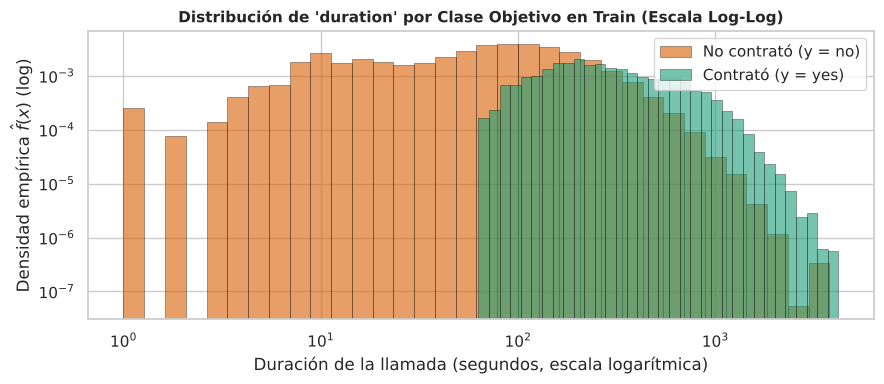

Columna 'duration' eliminada exitosamente de Train y Test.
Figura guardada en: 'figures/01_distribucion_duration_data_leakage.png'
Número de características restantes en entrenamiento: 19 (+ variable objetivo 'y')


In [5]:
# Visualización de la distribución logarítmica de duration por clase objetivo
fig, ax = plt.subplots(figsize=(9, 4))
for target_val, color, label in [("no", "#d95f02", "No contrató (y = no)"), ("yes", "#1b9e77", "Contrató (y = yes)")]:
    subset = ds_train[ds_train["y"] == target_val]["duration"]
    ax.hist(
        subset,
        bins=np.geomspace(max(1, subset.min()), subset.max(), 35),
        density=True,
        alpha=0.6,
        color=color,
        label=label,
        edgecolor="black",
        linewidth=0.4
    )

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title("Distribución de 'duration' por Clase Objetivo en Train (Escala Log-Log)", fontsize=11, fontweight="bold")
ax.set_xlabel("Duración de la llamada (segundos, escala logarítmica)")
ax.set_ylabel(r"Densidad empírica $\hat{f}(x)$ (log)")
ax.legend(frameon=True, loc="upper right")
plt.tight_layout()

# Guardar figura en alta resolución para la presentación
fig.savefig(os.path.join(FIGURES_PATH, "01_distribucion_duration_data_leakage.png"), dpi=300, bbox_inches="tight")
plt.show()

# Eliminación formal de duration para prevenir Data Leakage
ds_train = ds_train.drop(columns=["duration"])
ds_test = ds_test.drop(columns=["duration"])

print(f"Columna 'duration' eliminada exitosamente de Train y Test.")
print(f"Figura guardada en: 'figures/01_distribucion_duration_data_leakage.png'")
print(f"Número de características restantes en entrenamiento: {ds_train.shape[1] - 1} (+ variable objetivo 'y')")

## 6. Análisis Exploratorio de Datos (EDA) sobre el Conjunto de Entrenamiento

A continuación exploramos la estructura estadística de las variables utilizando **exclusivamente el conjunto de entrenamiento** para cumplir con los principios metodológicos de generalización.

Tratamos el balance de la variable objetivo (`y`) y la auditoría de la variable `default` en **secciones separadas**, ya que corresponden a conceptos analíticos independientes:
- **`y`** representa el comportamiento de conversión del cliente (variable dependiente a clasificar).
- **`default`** es un predictor de solvencia crediticia histórica (variable independiente categórica).

### 6.1 Balance de la Variable Objetivo (`y`)

El conjunto de entrenamiento refleja un marcado **desbalance de clases**:
- Clase negativa (`no`): $\approx 88.73\%$ ($29.229$ registros).
- Clase positiva (`yes`): $\approx 11.27\%$ ($3.711$ registros).

**Implicaciones metodológicas para el TP2:**
1. **Métricas de evaluación:** La exactitud (*Accuracy*) es una métrica engañosa (un clasificador trivial que prediga siempre `no` alcanzaría un $88.7\%$ de exactitud con utilidad comercial nula). Por eso evaluamos con **ROC-AUC** (capacidad de ordenar clientes, independiente del umbral) y **F1-Score de la clase minoritaria** (`yes`) (ver notebook 2).
2. **Validación cruzada:** El esquema de $k$-fold cross-validation debe ser **estratificado** (*Stratified $k$-Fold*) para asegurar que cada pliegue preserve la proporción $\approx 11.3\%$ de suscripciones.

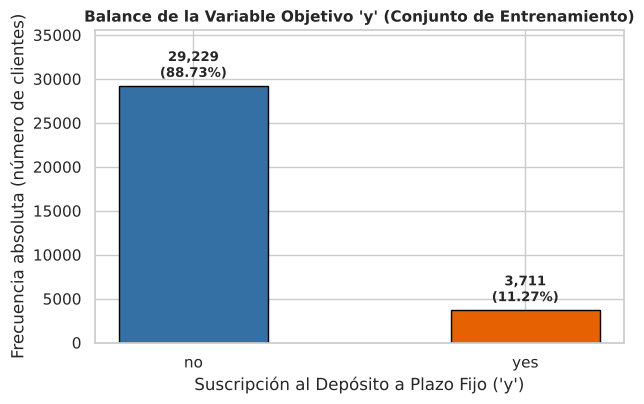

Figura guardada en: 'figures/02_balance_variable_objetivo.png'
Tasa positiva de suscripción en Train: 11.27%


In [6]:
# Gráfico independiente: Balance de la variable objetivo 'y'
fig, ax = plt.subplots(figsize=(6.5, 4.2))

y_counts = ds_train["y"].value_counts()
y_props = ds_train["y"].value_counts(normalize=True) * 100
bars = ax.bar(y_counts.index, y_counts.values, color=["#3470a3", "#e66101"], edgecolor="black", width=0.45)

ax.set_title("Balance de la Variable Objetivo 'y' (Conjunto de Entrenamiento)", fontsize=11, fontweight="bold")
ax.set_xlabel("Suscripción al Depósito a Plazo Fijo ('y')")
ax.set_ylabel("Frecuencia absoluta (número de clientes)")
ax.set_ylim(0, len(ds_train) * 1.08)

for bar, prop in zip(bars, y_props):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 500,
        f"{bar.get_height():,}\n({prop:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=9.5,
        fontweight="bold"
    )

plt.tight_layout()
fig.savefig(os.path.join(FIGURES_PATH, "02_balance_variable_objetivo.png"), dpi=300, bbox_inches="tight")
plt.show()

print(f"Figura guardada en: 'figures/02_balance_variable_objetivo.png'")
print(f"Tasa positiva de suscripción en Train: {(ds_train['y'] == 'yes').mean():.2%}")

### 6.2 Auditoría de Crédito en Mora (`default`)

La variable `default` indica si el cliente posee un historial crediticio en incumplimiento o mora.

**Hallazgos analíticos:**
- **`no`:** $79.18\%$ ($26.081$ clientes).
- **`unknown`:** $20.82\%$ ($6.857$ clientes).
- **`yes`:** **Únicamente 2 clientes en todo el conjunto de entrenamiento ($0.01\%$)**.

**Consecuencia para el modelado:**  
La categoría `'yes'` es prácticamente inexistente en la muestra. En la práctica, `default` opera como una variable cuasi-binaria entre información crediticia confirmada (`no`) y ausencia de datos (`unknown`). Esta observación justifica su codificación ordenada especial y explica por qué su aporte de información respecto a $y$ es marginal.

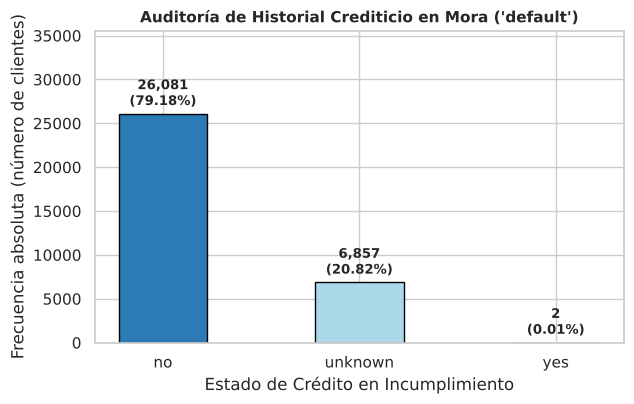

Figura guardada en: 'figures/03_auditoria_default.png'
Casos confirmados con default='yes' en Train: 2


In [7]:
# Gráfico independiente: Distribución y auditoría de la variable 'default'
fig, ax = plt.subplots(figsize=(6.5, 4.2))

default_counts = ds_train["default"].value_counts()
default_props = ds_train["default"].value_counts(normalize=True) * 100
bars = ax.bar(default_counts.index, default_counts.values, color=["#2c7bb6", "#abd9e9", "#d7191c"], edgecolor="black", width=0.45)

ax.set_title("Auditoría de Historial Crediticio en Mora ('default')", fontsize=11, fontweight="bold")
ax.set_xlabel("Estado de Crédito en Incumplimiento")
ax.set_ylabel("Frecuencia absoluta (número de clientes)")
ax.set_ylim(0, len(ds_train) * 1.08)

for bar, prop in zip(bars, default_props):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 500,
        f"{bar.get_height():,}\n({prop:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=9.5,
        fontweight="bold"
    )

plt.tight_layout()
fig.savefig(os.path.join(FIGURES_PATH, "03_auditoria_default.png"), dpi=300, bbox_inches="tight")
plt.show()

print(f"Figura guardada en: 'figures/03_auditoria_default.png'")
print(f"Casos confirmados con default='yes' en Train: {(ds_train['default'] == 'yes').sum()}")

### 6.3 Distribuciones Univariadas de Todas las Variables

Para caracterizar visualmente todas las características restantes sin alterar sus unidades naturales, aplicamos tres tratamientos diferenciados acordes a su naturaleza matemática:
1. **Histogramas de Densidad Continua:** Para variables continuas de espectro amplio (`euribor3m`).
2. **Funciones de Masa de Probabilidad de Aguja (Needle PMF):** Para variables discretas enteras o índices macroeconómicos multimodales (`age`, `campaign`, `pdays`, `previous`, `emp_var_rate`, `cons_price_idx`, `cons_conf_idx`, `nr_employed`).
   - Para `pdays`, se aísla el subconjunto efectivamente contactado ($pdays < 999$).
   - Para `campaign`, se utiliza eje horizontal logarítmico para visibilizar la cola larga de contactos.
3. **PMF de Barras Categóricas:** Para variables nominales u ordinales (`job`, `marital`, `education`, `housing`, `loan`, `contact`, `month`, `day_of_week`, `poutcome`), respetando el orden natural u ordenando por frecuencia decreciente.

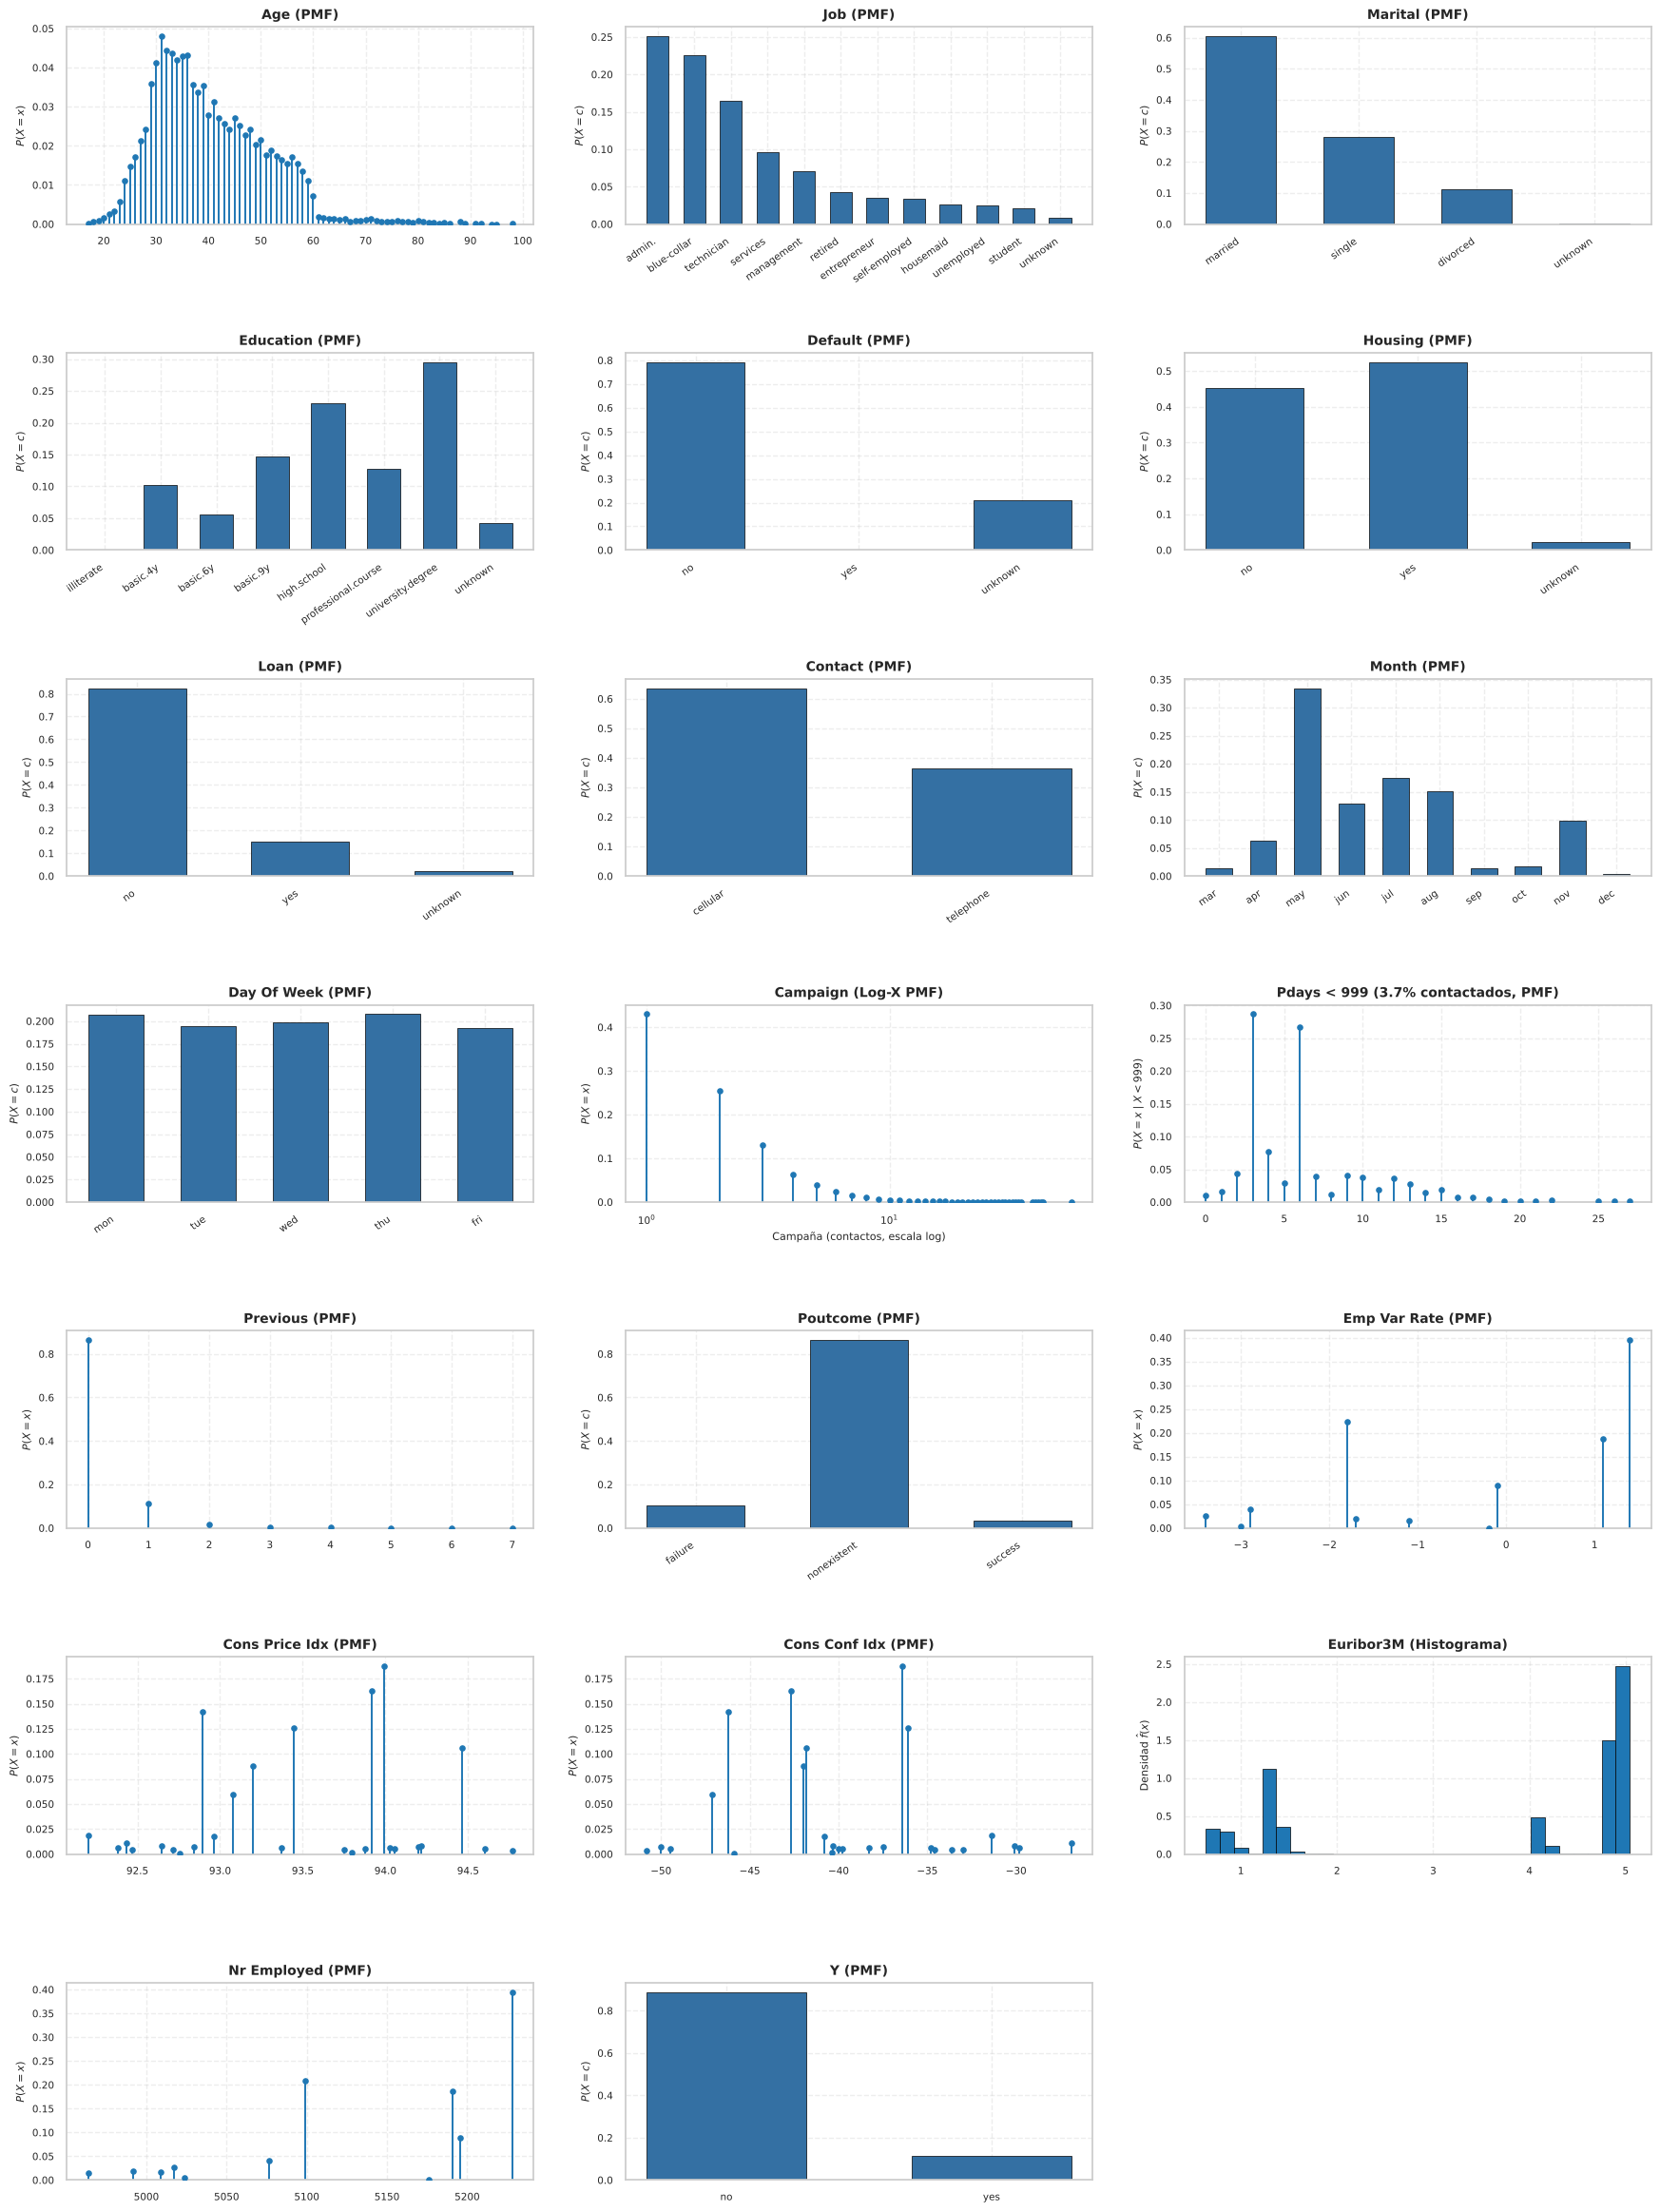

Figura guardada en: 'figures/04_distribuciones_univariadas.png'


In [8]:
# Definición de mapeos y tratamientos visuales
CONTINUOUS_HIST = {"euribor3m"}
NEEDLE_PMF = {
    "age", "campaign", "pdays", "previous",
    "emp_var_rate", "cons_price_idx", "cons_conf_idx", "nr_employed"
}
ORDERED_CATEGORIES = {
    "month": ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"],
    "day_of_week": ["mon", "tue", "wed", "thu", "fri"],
    "education": [
        "illiterate", "basic.4y", "basic.6y", "basic.9y",
        "high.school", "professional.course", "university.degree", "unknown"
    ],
    "default": ["no", "yes", "unknown"],
    "housing": ["no", "yes", "unknown"],
    "loan": ["no", "yes", "unknown"],
    "contact": ["cellular", "telephone"],
    "poutcome": ["failure", "nonexistent", "success"],
    "y": ["no", "yes"],
}

cols = list(ds_train.columns)
ncols = 3
nrows = int(np.ceil(len(cols) / ncols))

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(18, 3.4 * nrows))
axes = axes.flatten()

for i, col in enumerate(cols):
    ax = axes[i]
    rotate_labels = False

    # Tratamiento 1: Continuas (Histogramas de Densidad)
    if col in CONTINUOUS_HIST:
        s = pd.to_numeric(ds_train[col], errors="coerce").dropna().values
        ax.hist(s, bins=30, density=True, color="#1f77b4", edgecolor="black", linewidth=0.5)
        ax.set_title(f"{col.replace('_', ' ').title()} (Histograma)", fontsize=10, fontweight="bold")
        ax.set_ylabel(r"Densidad $\hat{f}(x)$", fontsize=8)

    # Tratamiento 2: Discretas / Macro (Needle PMF)
    elif col in NEEDLE_PMF:
        s = pd.to_numeric(ds_train[col], errors="coerce").dropna().values

        if col == "pdays":
            contacted = s[s < 999]
            pct_contacted = (len(contacted) / len(s)) * 100
            x_vals, counts = np.unique(contacted, return_counts=True)
            pmf = counts / len(contacted)

            ax.vlines(x_vals, ymin=0, ymax=pmf, color="#1f77b4", linewidth=1.4)
            ax.scatter(x_vals, pmf, color="#1f77b4", s=14, zorder=3)
            ax.set_title(f"Pdays < 999 ({pct_contacted:.1f}% contactados, PMF)", fontsize=10, fontweight="bold")
            ax.set_ylabel(r"$P(X = x \mid X < 999)$", fontsize=8)

        elif col == "campaign":
            x_vals, counts = np.unique(s[s > 0], return_counts=True)
            pmf = counts / len(s)

            ax.vlines(x_vals, ymin=0, ymax=pmf, color="#1f77b4", linewidth=1.4)
            ax.scatter(x_vals, pmf, color="#1f77b4", s=14, zorder=3)
            ax.set_xscale("log")
            ax.set_xlabel("Campaña (contactos, escala log)", fontsize=8)
            ax.set_title("Campaign (Log-X PMF)", fontsize=10, fontweight="bold")
            ax.set_ylabel(r"$P(X = x)$", fontsize=8)

        else:
            x_vals, counts = np.unique(s, return_counts=True)
            pmf = counts / len(s)

            ax.vlines(x_vals, ymin=0, ymax=pmf, color="#1f77b4", linewidth=1.4)
            ax.scatter(x_vals, pmf, color="#1f77b4", s=14, zorder=3)
            ax.set_title(f"{col.replace('_', ' ').title()} (PMF)", fontsize=10, fontweight="bold")
            ax.set_ylabel(r"$P(X = x)$", fontsize=8)

    # Tratamiento 3: Categóricas (Bar PMF)
    else:
        counts = ds_train[col].value_counts()
        total_obs = len(ds_train[col].dropna())

        if col in ORDERED_CATEGORIES:
            order = [c for c in ORDERED_CATEGORIES[col] if c in counts.index]
            remaining = [c for c in counts.index if c not in order]
            counts = counts.reindex(order + remaining, fill_value=0)
        else:
            counts = counts.sort_values(ascending=False)

        pmf = counts / total_obs
        labels = [str(k) for k in pmf.index]

        ax.bar(labels, pmf.values, width=0.6, color="#3470a3", edgecolor="black", linewidth=0.5)
        ax.set_ylabel(r"$P(X = c)$", fontsize=8)
        ax.set_title(f"{col.replace('_', ' ').title()} (PMF)", fontsize=10, fontweight="bold")
        rotate_labels = len(labels) > 3 or any(len(lbl) > 5 for lbl in labels)

    ax.set_ylim(bottom=0)
    ax.tick_params(axis="both", labelsize=7.5)
    ax.grid(True, linestyle="--", alpha=0.35)

    if rotate_labels:
        plt.setp(ax.get_xticklabels(), rotation=35, ha="right")

for j in range(len(cols), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout(pad=2.2)
fig.savefig(os.path.join(FIGURES_PATH, "04_distribuciones_univariadas.png"), dpi=300, bbox_inches="tight")
plt.show()

print(f"Figura guardada en: 'figures/04_distribuciones_univariadas.png'")

### 6.4 Diagnóstico de Valores Atípicos (*Outliers*)

- **Evaluación contextual:** Las variables numéricas en sus escalas naturales presentan rangos amplios pero plenamente legítimos en la realidad bancaria portuguesa (edades entre 17 y 98 años; tasas Euribor coherentes con el ciclo macroeconómico previo y posterior a la crisis financiera).
- **Tratamiento:** Dado el gran tamaño muestral ($N = 32.940$ en train) y la plausibilidad económica de las observaciones extremas, **no se realiza recorte o imputación artificial de outliers**. Esto evita la eliminación espuria de perfiles de clientes atípicos de alto valor crediticio.

## 7. Pipeline de Preprocesamiento y Transformación de Características

Para preparar los datos para los modelos supervisados preservando el rigor metodológico, estructuramos un `ColumnTransformer` modular:

1. **`education` (Codificación Ordinal):** Respeta la jerarquía intrínseca del nivel de escolaridad:  
   `illiterate` ($0$) $\to$ `basic.4y` ($1$) $\to$ `basic.6y` ($2$) $\to$ `basic.9y` ($3$) $\to$ `high.school` ($4$) $\to$ `professional.course` ($5$) $\to$ `university.degree` ($6$) $\to$ `unknown` ($7$).
2. **`default`, `housing`, `loan` (Codificación Ternaria Escalada):** Variables con estados $\{\text{'no'}, \text{'unknown'}, \text{'yes'}\}$. Se mapean ordenadamente a $[0.0, 0.5, 1.0]$ mediante `OrdinalEncoder` dividido por $2.0$.
3. **`contact` (Codificación Binaria):** Canal de comunicación: `telephone` ($0$), `cellular` ($1$).
4. **Nominales de mediana cardinalidad (`job`, `marital`, `month`, `day_of_week`, `poutcome`):** `OneHotEncoder(handle_unknown='ignore', sparse_output=False)` para expandir sus categorías sin imponer un orden artificial.
5. **Variables Numéricas Continuas y Discretas:** **SE CONSERVAN EN SU ESCALA ORIGINAL (`passthrough`, sin estandarizar)**.

> [!IMPORTANT]
> **Decisión crítica anti-leakage:**
> Las variables continuas (`age`, `campaign`, `pdays`, `previous`, `emp_var_rate`, `cons_price_idx`, `cons_conf_idx`, `euribor3m`, `nr_employed`) **no se estandarizan en este cuaderno**.
> Estandarizar previamente todo el conjunto de entrenamiento antes de la validación cruzada provocaría que los pliegues de validación interna se vean influenciados por la media y desviación estándar globales de la muestra completa. Por lo tanto, el escalado (`StandardScaler`) debe acoplarse dentro de un `Pipeline` en los cuadernos de modelado posteriores únicamente para los algoritmos que lo requieran (SVM, KNN).

In [9]:
def halve_values(x):
    """Escala valores ordinales [0, 1, 2] al intervalo [0.0, 0.5, 1.0]."""
    return x / 2.0

# 1. Separación de Variables Predictoras (X) y Objetivo (y)
y_train = ds_train["y"].map({"no": 0, "yes": 1}).astype(int)
X_train = ds_train.drop(columns=["y"])

y_test = ds_test["y"].map({"no": 0, "yes": 1}).astype(int)
X_test = ds_test.drop(columns=["y"])

# 2. Definición de Categorías y Subconjuntos de Columnas
ordinal_features = ["education"]
education_order = [[
    "illiterate", "basic.4y", "basic.6y", "basic.9y",
    "high.school", "professional.course", "university.degree", "unknown"
]]

ternary_features = ["default", "housing", "loan"]
ternary_order = [["no", "unknown", "yes"]] * len(ternary_features)

binary_features = ["contact"]
contact_order = [["telephone", "cellular"]]

nominal_features = ["job", "marital", "month", "day_of_week", "poutcome"]

numeric_features = [
    "age", "campaign", "pdays", "previous", "emp_var_rate",
    "cons_price_idx", "cons_conf_idx", "euribor3m", "nr_employed"
]

# 3. Construcción del Scikit-Learn ColumnTransformer (Sin StandardScaler)
preprocessor = ColumnTransformer(
    transformers=[
        (
            "ord",
            OrdinalEncoder(categories=education_order, handle_unknown="use_encoded_value", unknown_value=-1),
            ordinal_features
        ),
        (
            "ternary",
            Pipeline([
                (
                    "encoder",
                    OrdinalEncoder(categories=ternary_order, handle_unknown="use_encoded_value", unknown_value=-1)
                ),
                (
                    "scaler",
                    FunctionTransformer(halve_values, feature_names_out="one-to-one")
                ),
            ]),
            ternary_features
        ),
        (
            "bin",
            OrdinalEncoder(categories=contact_order, handle_unknown="use_encoded_value", unknown_value=-1),
            binary_features
        ),
        (
            "nom",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            nominal_features
        ),
        (
            "num",
            "passthrough",  # Sin estandarización previa: preserva unidades naturales anti-leakage
            numeric_features
        ),
    ],
    verbose_feature_names_out=False
)

# 4. Ajuste sobre X_train y Transformación de Ambos Conjuntos
X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()

# 5. Reconstrucción de DataFrames en memoria
ds_train_transformed = pd.DataFrame(
    X_train_transformed,
    columns=feature_names,
    index=X_train.index
)
ds_train_transformed["y"] = y_train.values

ds_test_transformed = pd.DataFrame(
    X_test_transformed,
    columns=feature_names,
    index=X_test.index
)
ds_test_transformed["y"] = y_test.values

print("=" * 65)
print("TRANSFORMACIÓN DE CARACTERÍSTICAS (SIN ESTANDARIZACIÓN PREVIA)")
print("=" * 65)
print(f"Dimensiones ds_train_transformed: {ds_train_transformed.shape[0]:>6,} filas × {ds_train_transformed.shape[1]} columnas")
print(f"Dimensiones ds_test_transformed:  {ds_test_transformed.shape[0]:>6,} filas × {ds_test_transformed.shape[1]} columnas")
print(f"Variables numéricas conservadas en su escala original para CV posterior.")
print("=" * 65)

TRANSFORMACIÓN DE CARACTERÍSTICAS (SIN ESTANDARIZACIÓN PREVIA)
Dimensiones ds_train_transformed: 32,940 filas × 49 columnas
Dimensiones ds_test_transformed:   8,236 filas × 49 columnas
Variables numéricas conservadas en su escala original para CV posterior.


## 8. Análisis de Dimensionalidad y Diagnóstico de Multicolinealidad

Para optimizar la capacidad predictiva y la fundamentación teórica de los clasificadores (Random Forest, SVM, Naive Bayes y KNN), aplicamos una batería de diagnósticos estadísticos:

### 1. Filtrado de Varianza Cuasi-Cero (*Near-Zero Variance - NZV*)
En variables generadas por *One-Hot Encoding*, categorías con prevalencias extremas ($p_j < 0.005$) poseen una varianza de Bernoulli marginal:
$$\text{Var}(X_j) = p_j (1 - p_j) < 0.005$$
Estas columnas cuasi-constantes no aportan entropía a los árboles de decisión, introducen subespacios singulares en SVM y colapsan las distancias en $k$-NN. Su descarte reduce el espacio dimensional sin merma de información.

### 2. Información Mutua Característica-Objetivo ($I(X_j; Y)$)
La Información Mutua cuantifica la reducción en la incertidumbre (entropía de Shannon) de la suscripción $Y$ condicionada a la característica $X_j$:
$$I(X_j; Y) = H(Y) - H(Y \mid X_j) = \sum_{y \in \{0, 1\}} \int p(x_j, y) \log \left(\frac{p(x_j, y)}{p(x_j)p(y)}\right) dx_j$$
$I(X_j; Y)$ detecta relaciones fuertemente no lineales y es invariante a la escala de las variables continuas.

### 3. Matriz de Dependencia entre Características (*Normalized Mutual Information - NMI*)
Identifica no linealidades cruzadas y redundancias entre pares de predictores mediante discretización por cuantiles.

### 4. Diagnóstico de Multicolinealidad Lineal (*Variance Inflation Factor - VIF*)
Calculado sobre los candidatos continuos con la adición de un término constante para diagnosticar colinealidad sistémica multivariada:
$$\text{VIF}_j = \frac{1}{1 - R_j^2}$$
Un $\text{VIF} > 10$ indica multicolinealidad severa, violando el supuesto de independencia condicional de Naive Bayes $\prod_{j=1}^p P(x_j \mid y)$ y generando inestabilidad numérica en hiperplanos regulares de SVM.

=== Paso 1: Filtrado de Varianza Cuasi-Cero (Var <= 0.005) ===
Total inicial de características: 48
Características eliminadas (NZV): 2
  [-] marital_unknown                (Var = 0.00206)
  [-] month_dec                      (Var = 0.00438)
Características retenidas:        46



=== Paso 2: Relevancia respecto al Objetivo (MI <= 0.005) ===
Características evaluadas:        46
Características descartadas (MI): 31
  [-] loan                           (MI = 0.00000 nats)
  [-] job_management                 (MI = 0.00000 nats)
  [-] day_of_week_tue                (MI = 0.00000 nats)
  [-] job_unknown                    (MI = 0.00000 nats)
  [-] job_housemaid                  (MI = 0.00001 nats)
  [-] day_of_week_fri                (MI = 0.00001 nats)
  [-] job_self-employed              (MI = 0.00002 nats)
  [-] month_aug                      (MI = 0.00002 nats)
  [-] day_of_week_wed                (MI = 0.00002 nats)
  [-] job_technician                 (MI = 0.00003 nats)
  [-] job_unemployed                 (MI = 0.00003 nats)
  [-] month_jun                      (MI = 0.00006 nats)
  [-] day_of_week_thu                (MI = 0.00006 nats)
  [-] month_nov                      (MI = 0.00006 nats)
  [-] marital_divorced               (MI = 0.00010 nats)
  [-] day

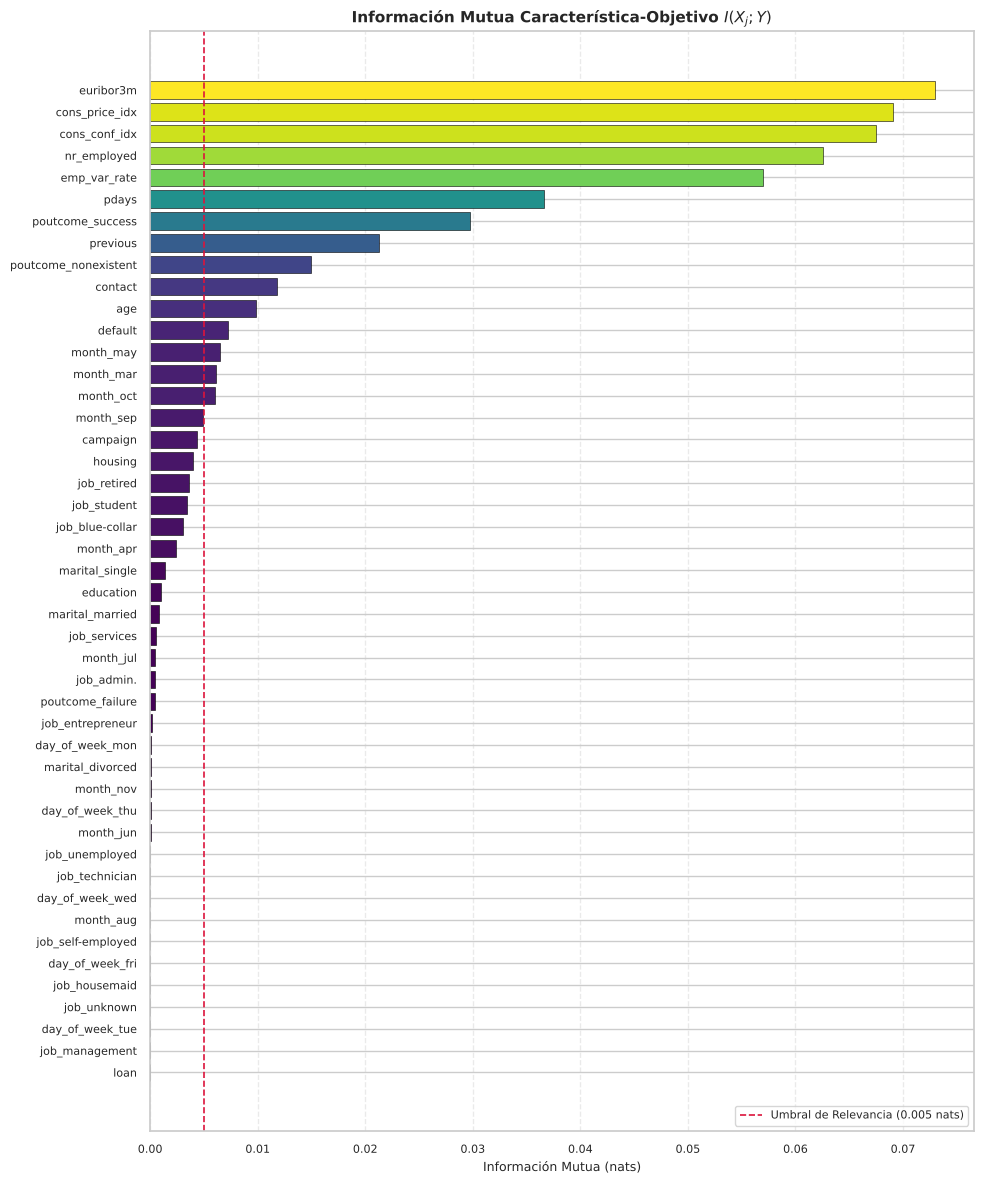

Figura guardada en: 'figures/05_informacion_mutua_relevancia.png'


In [10]:
# Separar variables predictoras y target en train transformado
X = ds_train_transformed.drop(columns=["y"])
y = ds_train_transformed["y"]

# -----------------------------------------------------------------------------
# Paso 1: Filtrado de Varianza Cuasi-Cero (NZV <= 0.005)
# -----------------------------------------------------------------------------
nzv_selector = VarianceThreshold(threshold=0.005)
nzv_selector.fit(X)

variances = pd.Series(X.var(), index=X.columns)
retained_after_nzv = X.columns[nzv_selector.get_support()].tolist()
dropped_nzv = X.columns[~nzv_selector.get_support()].tolist()

print("[1m=== Paso 1: Filtrado de Varianza Cuasi-Cero (Var <= 0.005) ===[0m")
print(f"Total inicial de características: {X.shape[1]}")
print(f"Características eliminadas (NZV): {len(dropped_nzv)}")
for col in dropped_nzv:
    print(f"  [-] {col:<30} (Var = {variances[col]:.5f})")
print(f"Características retenidas:        {len(retained_after_nzv)}\n")

X_step1 = X[retained_after_nzv]

# -----------------------------------------------------------------------------
# Paso 2: Información Mutua Característica-Objetivo I(X; Y)
# -----------------------------------------------------------------------------
mi_threshold = 0.005
binary_mask = (X_step1.nunique() <= 2).values  # columnas 0/1 (one-hot y binarias) → estimador discreto
mi_scores = mutual_info_classif(X_step1, y, discrete_features=binary_mask, random_state=RANDOM_STATE)
mi_series = pd.Series(mi_scores, index=X_step1.columns).sort_values(ascending=True)

dropped_mi = mi_series[mi_series <= mi_threshold].index.tolist()
selected_features = mi_series[mi_series > mi_threshold].index.tolist()

print("[1m=== Paso 2: Relevancia respecto al Objetivo (MI <= 0.005) ===[0m")
print(f"Características evaluadas:        {len(mi_series)}")
print(f"Características descartadas (MI): {len(dropped_mi)}")
for col in dropped_mi:
    print(f"  [-] {col:<30} (MI = {mi_series[col]:.5f} nats)")
print(f"Características seleccionadas:    {len(selected_features)}\n")

# Gráfico de barras horizontal ordenado
fig_h = max(6, int(len(mi_series) * 0.28))
fig, ax = plt.subplots(figsize=(10, fig_h))
norm = plt.Normalize(mi_series.min(), mi_series.max())
colors = plt.cm.viridis(norm(mi_series.values))

ax.barh(mi_series.index, mi_series.values, color=colors, edgecolor="black", linewidth=0.4)
ax.axvline(
    x=mi_threshold,
    color="crimson",
    linestyle="--",
    linewidth=1.2,
    label=f"Umbral de Relevancia ({mi_threshold} nats)",
)
ax.set_title(r"Información Mutua Característica-Objetivo $I(X_j; Y)$", fontsize=11, fontweight="bold")
ax.set_xlabel("Información Mutua (nats)", fontsize=9)
ax.tick_params(axis="both", labelsize=8)
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()

fig.savefig(os.path.join(FIGURES_PATH, "05_informacion_mutua_relevancia.png"), dpi=300, bbox_inches="tight")
plt.show()

print(f"Figura guardada en: 'figures/05_informacion_mutua_relevancia.png'")
X_selected = X_step1[selected_features]

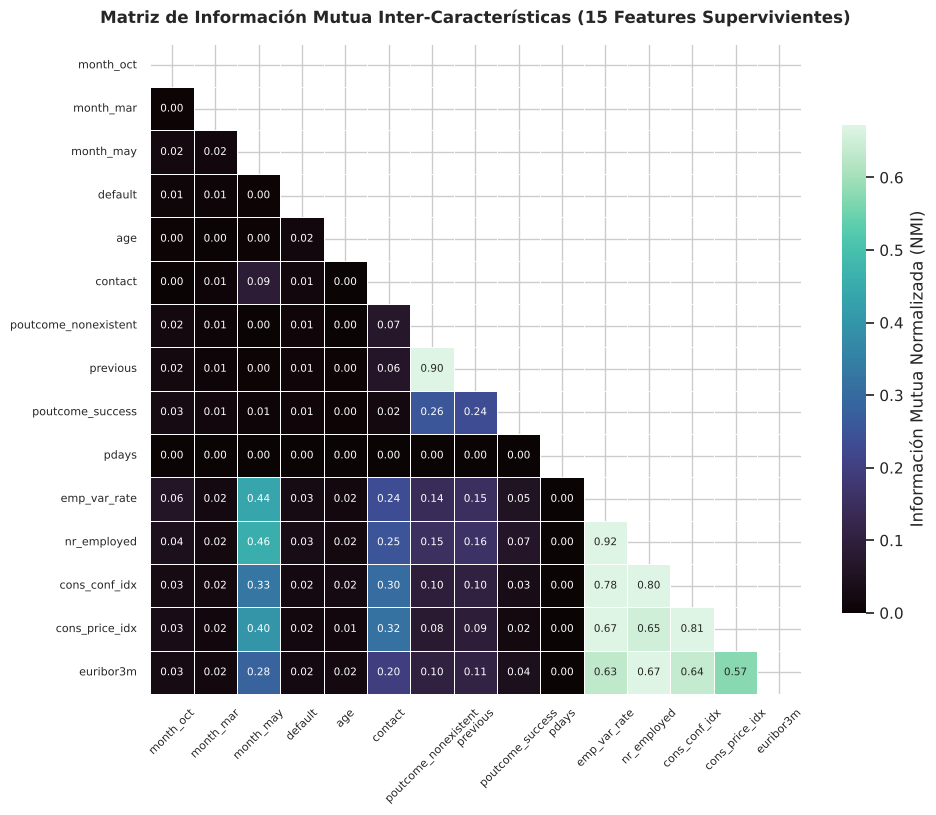

Figura guardada en: 'figures/06_matriz_dependencia_nmi.png'
=== Paso 3B: Diagnóstico de Multicolinealidad (VIF) ===
Característica                   VIF  Diagnóstico
-------------------------------------------------------
euribor3m                      64.00  Multicolinealidad Severa (> 10)
emp_var_rate                   33.12  Multicolinealidad Severa (> 10)
nr_employed                    31.42  Multicolinealidad Severa (> 10)
cons_price_idx                  6.33  Aceptable (< 10)
cons_conf_idx                   2.64  Aceptable (< 10)
previous                        1.79  Aceptable (< 10)
pdays                           1.62  Aceptable (< 10)
age                             1.02  Aceptable (< 10)


In [11]:
# -----------------------------------------------------------------------------
# Paso 3A: Matriz de Información Mutua Normalizada Inter-Características (NMI)
# -----------------------------------------------------------------------------
X_discrete = X_selected.copy()
for col in X_discrete.columns:
    if X_discrete[col].nunique() > 10:
        X_discrete[col] = pd.qcut(X_discrete[col], q=10, labels=False, duplicates="drop")
    else:
        X_discrete[col] = pd.factorize(X_discrete[col])[0]

n_feats = X_discrete.shape[1]
feat_names = X_discrete.columns
mi_mat = np.zeros((n_feats, n_feats))

for i in range(n_feats):
    for j in range(i, n_feats):
        if i == j:
            val = 1.0
        else:
            val = normalized_mutual_info_score(X_discrete.iloc[:, i], X_discrete.iloc[:, j])
        mi_mat[i, j] = val
        mi_mat[j, i] = val

dep_matrix = pd.DataFrame(mi_mat, index=feat_names, columns=feat_names)
mask = np.triu(np.ones_like(dep_matrix, dtype=bool))

off_diag_vals = dep_matrix.values[np.tril_indices_from(dep_matrix, k=-1)]
vmax_val = float(np.clip(np.percentile(off_diag_vals, 95), 0.25, 1.0)) if len(off_diag_vals) > 0 else 1.0

matrix_dim = max(10, int(len(selected_features) * 0.65))
fig, ax = plt.subplots(figsize=(matrix_dim, matrix_dim * 0.82))

sns.heatmap(
    dep_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="mako",
    vmin=0,
    vmax=vmax_val,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": r"Información Mutua Normalizada (NMI)", "shrink": 0.75},
    annot_kws={"size": 7.5},
    ax=ax
)
ax.set_title(
    f"Matriz de Información Mutua Inter-Características ({len(selected_features)} Features Supervivientes)",
    fontsize=12,
    fontweight="bold",
    pad=15,
)
ax.tick_params(axis="x", labelsize=8, rotation=45)
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()

fig.savefig(os.path.join(FIGURES_PATH, "06_matriz_dependencia_nmi.png"), dpi=300, bbox_inches="tight")
plt.show()

print(f"Figura guardada en: 'figures/06_matriz_dependencia_nmi.png'")

# -----------------------------------------------------------------------------
# Paso 3B: Diagnóstico de Multicolinealidad Lineal (VIF con Constante)
# -----------------------------------------------------------------------------
continuous_candidates = [
    "euribor3m",
    "cons_conf_idx",
    "cons_price_idx",
    "nr_employed",
    "emp_var_rate",
    "pdays",
    "previous",
    "age",
    "campaign",
]
continuous_selected = [c for c in continuous_candidates if c in selected_features]

# Ajuste con constante para calcular VIF correcto en escalas no estandarizadas
X_vif_input = add_constant(X_selected[continuous_selected])
vif_values = [
    variance_inflation_factor(X_vif_input.values, i + 1)
    for i in range(len(continuous_selected))
]

vif_data = pd.DataFrame({"Feature": continuous_selected, "VIF": vif_values})
vif_data = vif_data.sort_values(by="VIF", ascending=False).reset_index(drop=True)

print("[1m=== Paso 3B: Diagnóstico de Multicolinealidad (VIF) ===[0m")
print(f"{'Característica':<25} {'VIF':>10}  {'Diagnóstico'}")
print("-" * 55)
for _, row in vif_data.iterrows():
    val = row["VIF"]
    status = "[91mMulticolinealidad Severa (> 10)[0m" if val > 10 else "[92mAceptable (< 10)[0m"
    print(f"{row['Feature']:<25} {val:>10.2f}  {status}")

## 9. Construcción y Exportación de los 3 Subconjuntos Curados en `data/`

Con base en los diagnósticos empíricos precedentes y en concordancia con los requerimientos teóricos de cada familia algorítmica especificada en las consignas del TP2, conformamos **únicamente tres datasets finales** y los almacenamos en la carpeta `data/`:

### **Set 1: High-Capacity Ensemble Set (14 Variables + Target)**
- **Modelo destinatario:** **Random Forest**.
- **Fundamento:** Las arquitecturas basadas en ensambles de árboles aíslan fronteras de decisión ortogonales mediante cortes recursivos y son intrínsecamente invariantes a la multicolinealidad monótona. Este conjunto maximiza la retención de señal: conserva las 15 variables que superan el umbral de Información Mutua (todos los indicadores macroeconómicos, el historial de contacto, `default`, `age`, `contact` y los meses `month_may`, `month_mar` y `month_oct`), excepto `poutcome_nonexistent`, excluida por su redundancia determinista con `previous` ($\text{NMI} = 0.90$).

### **Set 2: Collinearity-Resolved Core Set (7 Variables + Target)**
- **Modelos destinatarios:** **SVM (Kernel RBF)** y **Gaussian Naive Bayes**.
- **Fundamento:** El bloque macroeconómico exhibe inflación de varianza extrema ($\text{VIF} > 30$ para `emp_var_rate` y `nr_employed`), lo que destruye el supuesto de independencia condicional de Naive Bayes $\prod_{j=1}^p P(x_j \mid y)$ y desestabiliza los hiperplanos regularizados de SVM. Conservamos únicamente `euribor3m` ($I = 0.071$) como el principal conductor macroeconómico y `cons_conf_idx` ($\text{VIF} = 2.64$) como proxy de sentimiento del consumidor, garantizando $\text{VIF} < 3.0$ en todos los predictores continuos.

### **Set 3: Minimalist Orthogonal Set (5 Variables + Target)**
- **Modelo destinatario:** **K-Nearest Neighbors (KNN)**.
- **Fundamento:** Mitigación directa de la *maldición de la dimensionalidad* (*curse of dimensionality*). En espacios euclidianos de dimensión creciente $p$, el volumen crece exponencialmente y las distancias entre pares convergen a la uniformidad:
  $$\lim_{p \to \infty} \frac{\text{dist}_{\max} - \text{dist}_{\min}}{\text{dist}_{\min}} \to 0$$
  Este subconjunto minimalista selecciona exactamente **un único representante ortogonal** por cada dimensión del dominio:
  1. *Contexto macroeconómico:* `euribor3m`
  2. *Memoria de contacto:* `pdays`
  3. *Historial de conversión previa:* `poutcome_success`
  4. *Canal de comunicación:* `contact`
  5. *Ciclo de vida demográfico:* `age`

> **Nota:** la asignación de cada set a un modelo es la hipótesis inicial. En el notebook 2 se comparan los 3 sets con los 4 modelos mediante validación cruzada, y se elige el **set 1 para los 4 modelos**, porque obtiene igual o mejor ROC-AUC en todos.

In [12]:
# -----------------------------------------------------------------------------
# 1. Definición Formal de Subconjuntos de Características Curados
# -----------------------------------------------------------------------------
feature_subsets = {
    "set1_high_capacity": [
        "euribor3m",
        "cons_conf_idx",
        "cons_price_idx",
        "nr_employed",
        "emp_var_rate",
        "pdays",
        "poutcome_success",
        "previous",
        "contact",
        "age",
        "default",
        "month_may",
        "month_mar",
        "month_oct",
    ],
    "set2_core_decorrelated": [
        "euribor3m",
        "cons_conf_idx",
        "pdays",
        "poutcome_success",
        "previous",
        "contact",
        "age",
    ],
    "set3_minimalist_knn": [
        "euribor3m",
        "pdays",
        "poutcome_success",
        "contact",
        "age",
    ],
}

print("=" * 70)
print("EXPORTACIÓN EXCLUSIVA DE LOS 3 DATASETS CURADOS EN 'data/'")
print("=" * 70)

exported_summary = []

for set_name, features in feature_subsets.items():
    cols_to_extract = features + ["y"]

    # Verificación estricta de columnas en Train y Test
    missing_train = [c for c in cols_to_extract if c not in ds_train_transformed.columns]
    missing_test = [c for c in cols_to_extract if c not in ds_test_transformed.columns]
    if missing_train or missing_test:
        raise KeyError(f"Error en {set_name}: Faltan {missing_train} en Train o {missing_test} en Test.")

    # Guardar subconjunto de Entrenamiento en data/
    train_subset = ds_train_transformed[cols_to_extract]
    train_path = os.path.join(DATA_PATH, f"ds_train_{set_name}.csv")
    train_subset.to_csv(train_path, index=False)
    exported_summary.append((train_path, train_subset.shape))

    # Guardar subconjunto de Evaluación (Test) en data/
    test_subset = ds_test_transformed[cols_to_extract]
    test_path = os.path.join(DATA_PATH, f"ds_test_{set_name}.csv")
    test_subset.to_csv(test_path, index=False)
    exported_summary.append((test_path, test_subset.shape))

for fpath, shape in exported_summary:
    print(f"Archivo exportado: {os.path.basename(fpath):<38} | {shape[0]:>5,} filas × {shape[1]:>2} columnas")

print("=" * 70)
print("Exportación completa. Únicamente los 3 datasets curados fueron persistidos en 'data/'.")

EXPORTACIÓN EXCLUSIVA DE LOS 3 DATASETS CURADOS EN 'data/'


Archivo exportado: ds_train_set1_high_capacity.csv        | 32,940 filas × 15 columnas
Archivo exportado: ds_test_set1_high_capacity.csv         | 8,236 filas × 15 columnas
Archivo exportado: ds_train_set2_core_decorrelated.csv    | 32,940 filas ×  8 columnas
Archivo exportado: ds_test_set2_core_decorrelated.csv     | 8,236 filas ×  8 columnas
Archivo exportado: ds_train_set3_minimalist_knn.csv       | 32,940 filas ×  6 columnas
Archivo exportado: ds_test_set3_minimalist_knn.csv        | 8,236 filas ×  6 columnas
Exportación completa. Únicamente los 3 datasets curados fueron persistidos en 'data/'.


## 10. Resumen Ejecutivo y Conexión con los Siguientes Notebooks

### Subconjuntos Exportados en `data/`:
| Archivo en `data/` | Variables | Algoritmos Destinatarios en TP2 | Justificación Metodológica |
| :--- | :---: | :--- | :--- |
| **`ds_train_set1_high_capacity.csv`**<br>`ds_test_set1_high_capacity.csv` | 14 + $y$ | **Random Forest** | Retiene señales macroeconómicas complejas y estacionalidad de calendario; resistente a colinealidad. |
| **`ds_train_set2_core_decorrelated.csv`**<br>`ds_test_set2_core_decorrelated.csv` | 7 + $y$ | **SVM (Kernel RBF)** y<br>**Gaussian Naive Bayes** | Elimina redundancias macroeconómicas y variables fragmentadas; garantiza $\text{VIF} < 3.0$. |
| **`ds_train_set3_minimalist_knn.csv`**<br>`ds_test_set3_minimalist_knn.csv` | 5 + $y$ | **K-Nearest Neighbors (KNN)** | Selección ortogonal de 1 variable por dimensión; mitiga la maldición de la dimensionalidad. |

### Figuras de Presentación Exportadas en `figures/`:
1. `01_distribucion_duration_data_leakage.png`: Justificación visual de exclusión de `duration` por fuga de información.
2. `02_balance_variable_objetivo.png`: Distribución y desbalance de la variable objetivo $y$ ($88.74\%$ vs $11.26\%$).
3. `03_auditoria_default.png`: Auditoría de solvencia crediticia y justificación de comportamiento cuasi-binario.
4. `04_distribuciones_univariadas.png`: Rejilla completa de densidades y PMFs en escalas originales.
5. `05_informacion_mutua_relevancia.png`: Ranking de Información Mutua respecto al objetivo con umbral crítico.
6. `06_matriz_dependencia_nmi.png`: Mapa de calor de Información Mutua Normalizada inter-características.

---
> **Nota:** la asignación de cada set a un modelo es la hipótesis inicial. En el notebook 2 se comparan los 3 sets con los 4 modelos mediante validación cruzada, y se elige el **set 1 para los 4 modelos**, porque obtiene igual o mejor ROC-AUC en todos.

**Próximos pasos en el TP2:**
1. Comparación de los 3 subconjuntos con los modelos supervisados (**Naive Bayes, SVM, KNN, Random Forest**) utilizando validación cruzada $k$-fold estratificada exclusivamente sobre los conjuntos de entrenamiento en `data/`.
2. Integración de `StandardScaler` dentro de `Pipeline` de Scikit-Learn en los modelos sensibles a la escala (SVM y KNN) para garantizar cero fuga de información entre pliegues.
3. Ajuste de hiperparámetros mediante curvas de validación y análisis de overfitting / underfitting.